In [35]:
import numpy as np
from matplotlib import pyplot as plt

#### a) Markov Transition Matrix
There are 10 levels, in each turn, the levels can increase by 1 or decrease by 1 step. It cannot stay the same or increase 2 or more steps. The edge cases include level 10, where mood state can only go down by 1 at 0.1 chance, and level 1, where the probability of it staying 1 is 1.

In [36]:
sales_prob = np.arange(0, 1, 0.1)
trans_matrix = np.zeros((10, 10))

for i in range(1,9):
    trans_matrix[i,i+1] = sales_prob[i]
    trans_matrix[i,i-1] = 1 - sales_prob[i]

# Edge cases
trans_matrix[0, 0] = 1.0
trans_matrix[9, 9] = 0.9
trans_matrix[9,8] = 1 - sales_prob[9]
    
print(trans_matrix)

[[1.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.9 0.  0.1 0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.8 0.  0.2 0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.7 0.  0.3 0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.6 0.  0.4 0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.5 0.  0.5 0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.4 0.  0.6 0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.3 0.  0.7 0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.2 0.  0.8]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.1 0.9]]


#### b) Simulation and Visualization

In [37]:
T = 1000
simulations = 10000

In [38]:
sales_matrix = np.zeros((10,simulations))
time_to_5 = np.zeros((10,simulations))

for i in range (1,10):
    for j in range(simulations):
        state = i
        for t in range(T):
            if sales_matrix[i][j] < 5:
                time_to_5[i][j] += 1
            success = np.random.binomial(1, sales_prob[state])
            sales_matrix[i][j] += success
            if success:
                state = np.minimum(state + 1, 9)
            else:
                state = np.maximum(state - 1, 0)
            
        if time_to_5[i][j] == 1000 and sales_matrix[i][j] < 5:
            time_to_5[i][j] += 1

            

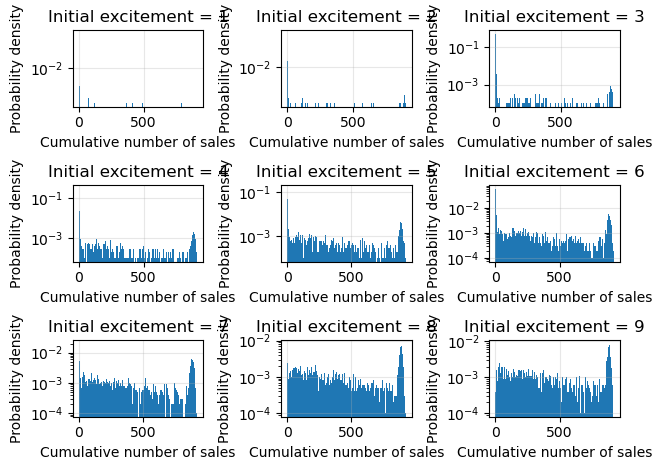

In [39]:
fig, axes = plt.subplots(3, 3)

for i in range(9):
    
    ax = axes.flat[i]
    data = sales_matrix[i + 1]
    
    bins = np.arange(data.min() - 0.5, data.max() + 1.5, 1)
    
    ax.hist(data, bins=bins, density=True)
    
    ax.set_yscale("log")
    ax.set_xlabel("Cumulative number of sales")
    ax.set_ylabel("Probability density")
    ax.set_title(f"Initial excitement = {i + 1}")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### c) Plot the average sales

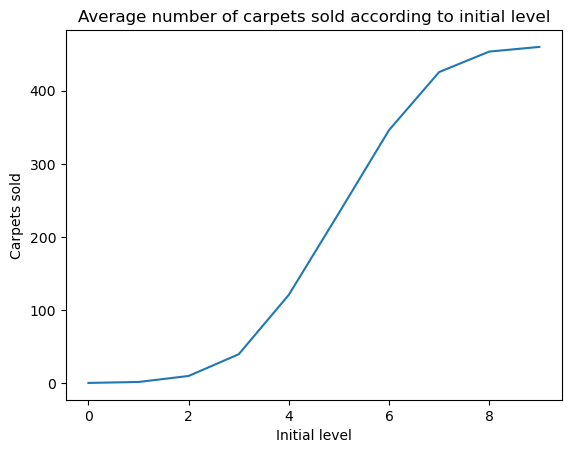

In [40]:
average_sales = np.mean(sales_matrix, axis = 1)
plt.plot(average_sales)
plt.xlabel("Initial level")
plt.ylabel("Carpets sold")
plt.title("Average number of carpets sold according to initial level")

plt.show()

#### d) PMF for number of steps to getting to 5 carpets
Y log-scale was used to show the decay functional form. 

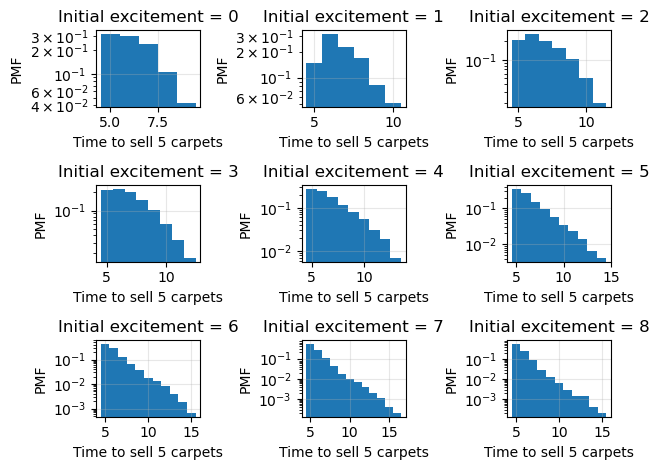

In [41]:
fig, axes = plt.subplots(3, 3)
average_times = np.zeros(9)

for i in range(9):
    
    ax = axes.flat[i]
    times = time_to_5[i+1]
    times = np.asarray([a for a in times if a <= 1000])
    average_times[i] = np.mean(times)
    
    bins = np.arange(times.min() - 0.5, times.max() + 1.5, 1)
    
    ax.hist(times, bins=bins, density=True)
    
    ax.set_yscale("log")
    ax.set_xlabel("Time to sell 5 carpets")
    ax.set_ylabel("PMF")
    ax.set_title(f"Initial excitement = {i}")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### e) Average steps to getting to 5 carpets

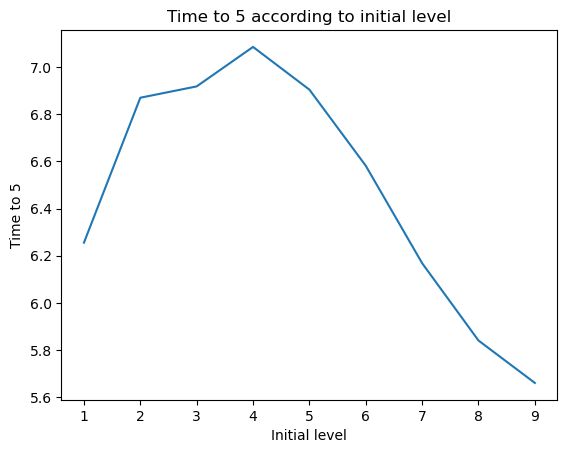

In [42]:
plt.plot(range(1,10),average_times)
plt.xlabel("Initial level")
plt.ylabel("Time to 5")
plt.title("Time to 5 according to initial level")

plt.show()

#### f) Probability of selling less than 5 carpets

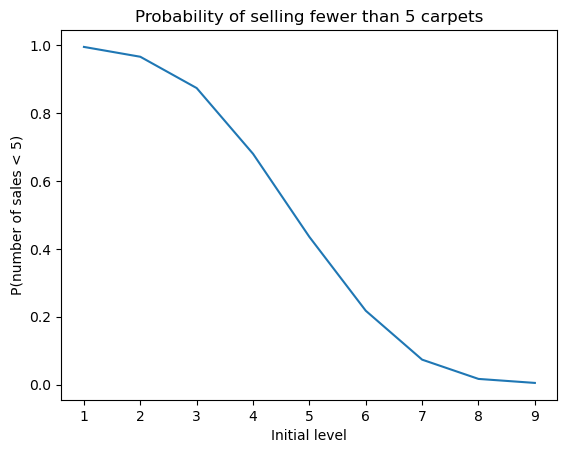

In [43]:
p_under_5 = np.zeros(9)
for i in range(9):
    times = time_to_5[i + 1]
    less_5 = np.array([a for a in times if a > 1000])
    p_under_5[i] = len(less_5) / simulations
    
    
# Plotting
plt.plot(range(1,10), p_under_5)

plt.xlabel("Initial level")
plt.ylabel("P(number of sales < 5)")
plt.title("Probability of selling fewer than 5 carpets")
plt.show()

#### g) 
Salesmen has a higher chance of selling more carpets when they start with high excitement level. The waiting time for another the sales is similar to the waiting time of success in the approximately constant success probability => the current process produces exponential functional form.